In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!nvidia-smi
!nvcc --version
import torch
print("torch", torch.__version__, "| cuda", torch.version.cuda, "| gpu dispo :", torch.cuda.is_available())

Wed Oct 28 22:36:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
CONDITION = "snow"
SNOW_IMAGES_DIR = None
N_IMAGES = 200
IMG_WIDTH = 1600
SNOW_SEED = 1234
SNOW_DENSITY = 5000
ITERATIONS = 7000
EVAL_HOLD = 8
ZIP_URL = "https://zenodo.org/records/21824088/files/Abyssal.zip?download=1"
KEY = "kwaj"
EXCLUDE = ("model", "mesh", "ortho", "dem", "photogrammetry")
GS_COMMIT = "HASH_COMMUN"
SELECTION_HASH = "A_REMPLIR"
WORK = "/kaggle/working"
GS = f"{WORK}/gaussian-splatting"
CLEAN_DIR = f"{WORK}/clean_resized"
SCENE = f"{WORK}/scene_{CONDITION}"
INPUT_DIR = f"{SCENE}/input"
OUT = f"{WORK}/output_{CONDITION}"

In [4]:
import os, zipfile, collections

ZIP_PATH = f"{WORK}/Abyssal.zip"
if not os.path.exists(ZIP_PATH):
    !wget -q --show-progress -O {ZIP_PATH} "{ZIP_URL}"
!ls -lh {ZIP_PATH}
!md5sum {ZIP_PATH}

z = zipfile.ZipFile(ZIP_PATH)
names_all = z.namelist()
print(len(names_all), "entrees dans le zip")
for n in names_all[:40]:
    print(n)
kw = [n for n in names_all if KEY in n.lower()]
print(len(kw), "entrees contenant", KEY)
print(collections.Counter(os.path.splitext(n)[1].lower() for n in kw))

/kaggle/working/Aby 100%[===================>]   2.82G   122MB/s    in 6m 53s  
-rw-r--r-- 1 root root 2.9G Oct 28 22:43 /kaggle/working/Abyssal.zip
b265eb763ca043f66b7fa226e0bc2a7d  /kaggle/working/Abyssal.zip
6021 entrees dans le zip
ISRO/
ISRO/train/
ISRO/train/depth_any/
ISRO/train/depth_any/0009.png
ISRO/train/depth_any/0010.png
ISRO/train/depth_any/0011.png
ISRO/train/depth_any/0012.png
ISRO/train/depth_any/0013.png
ISRO/train/depth_any/0014.png
ISRO/train/depth_any/0015.png
ISRO/train/depth_any/0016.png
ISRO/train/depth_any/0017.png
ISRO/train/depth_any/0018.png
ISRO/train/depth_any/0019.png
ISRO/train/depth_any/0020.png
ISRO/train/depth_any/0021.png
ISRO/train/depth_any/0022.png
ISRO/train/depth_any/0023.png
ISRO/train/depth_any/0024.png
ISRO/train/depth_any/0025.png
ISRO/train/depth_any/0026.png
ISRO/train/depth_any/0027.png
ISRO/train/depth_any/0029.png
ISRO/train/depth_any/0030.png
ISRO/train/depth_any/0031.png
ISRO/train/depth_any/0032.png
ISRO/train/depth_any/0055.png
ISRO

In [5]:
import re, json, hashlib, shutil, numpy as np, cv2

IMG_EXT = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]

cands = sorted((n for n in names_all
                if KEY in n.lower() and n.lower().endswith(IMG_EXT)
                and not any(x in n.lower() for x in EXCLUDE)),
               key=natural_key)
print(len(cands), "images candidates (attendu : 1294)")
assert len(cands) == 1294, "Ajuster KEY / EXCLUDE d'apres le listing (cellule 4a)"

idx = np.round(np.linspace(0, len(cands) - 1, N_IMAGES)).astype(int)
assert len(set(idx.tolist())) == N_IMAGES
selected = [cands[i] for i in idx]

sel_hash = hashlib.sha256("\n".join(selected).encode()).hexdigest()
print("SELECTION_HASH :", sel_hash)
if SELECTION_HASH != "A_REMPLIR":
    assert sel_hash == SELECTION_HASH, "selection differente de celle de Ranim : verifier KEY, EXCLUDE, N_IMAGES"

os.makedirs(CLEAN_DIR, exist_ok=True)
images = []
for k, name in enumerate(selected):
    buf = np.frombuffer(z.read(name), np.uint8)
    img = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    h, w = img.shape[:2]
    if w > IMG_WIDTH:
        img = cv2.resize(img, (IMG_WIDTH, round(h * IMG_WIDTH / w)),
                         interpolation=cv2.INTER_AREA)
    new = f"{k:05d}.png"
    cv2.imwrite(f"{CLEAN_DIR}/{new}", img)
    images.append(dict(new=new, original=name, index_in_sequence=int(idx[k]),
                       shape=list(img.shape),
                       pixel_sha256=hashlib.sha256(img.tobytes()).hexdigest()))

assert len({tuple(m["shape"]) for m in images}) == 1, "tailles d'images differentes"
names = sorted(os.listdir(CLEAN_DIR))
assert names == [f"{i:05d}.png" for i in range(N_IMAGES)]

json.dump(dict(selection_hash=sel_hash, images=images),
          open(f"{WORK}/manifest_clean_{CONDITION}.json", "w"), indent=1)
print(len(names), "images propres ->", CLEAN_DIR, "| taille :", images[0]["shape"])
!rm -f {ZIP_PATH}

1294 images candidates (attendu : 1294)
SELECTION_HASH : 8bfe447973664727ecd0f5557338651ac628f3d949063efe33f7954932000211
200 images propres -> /kaggle/working/clean_resized | taille : [536, 960, 3]


In [6]:
import glob, hashlib

os.makedirs(INPUT_DIR, exist_ok=True)

if CONDITION == "clean":
    for f in names:
        shutil.copy(f"{CLEAN_DIR}/{f}", f"{INPUT_DIR}/{f}")

elif SNOW_IMAGES_DIR is not None:
    mp2 = glob.glob(f"{SNOW_IMAGES_DIR}/**/manifest_snow.json", recursive=True)[0]
    sdir = os.path.dirname(mp2)
    sman = json.load(open(mp2))
    assert [m["new"] for m in sman["images"]] == names, "ordre ou noms differents des images propres"
    for m in sman["images"]:
        raw = open(f"{sdir}/{m['new']}", "rb").read()
        assert hashlib.sha256(raw).hexdigest() == m["sha256"], f"image neige alteree : {m['new']}"
        shutil.copy(f"{sdir}/{m['new']}", f"{INPUT_DIR}/{m['new']}")
    print("parametres de la neige :", sman["params"])

else:
    snow_name = f"kwaj-snow-d{SNOW_DENSITY}-200"
    share = f"{WORK}/{snow_name}"
    os.makedirs(share, exist_ok=True)
    images_snow = []
    for f in names:
        i = int(f[:5])
        img = cv2.imread(f"{CLEAN_DIR}/{f}").astype(np.float32) / 255.0
        h, w = img.shape[:2]
        s = 1.0
        rng = np.random.default_rng(SNOW_SEED + i)
        sharp = np.zeros((h, w), np.float32)
        blurry = np.zeros((h, w), np.float32)
        n = int(SNOW_DENSITY * (w * h) / (1600 * 1600 * 0.75))
        for _ in range(n):
            x, y = int(rng.uniform(0, w)), int(rng.uniform(0, h))
            r = max(1, int(rng.lognormal(0.3, 0.6) * s))
            axes = (r, max(1, int(r * rng.uniform(0.6, 1.0))))
            layer = blurry if rng.random() < 0.3 else sharp
            cv2.ellipse(layer, (x, y), axes, rng.uniform(0, 180), 0, 360,
                        float(rng.uniform(0.3, 1.0)), -1)
        sharp = cv2.GaussianBlur(sharp, (0, 0), 0.8 * s)
        blurry = cv2.GaussianBlur(blurry, (0, 0), 4.0 * s)
        alpha = np.clip(0.8 * sharp + 0.5 * blurry, 0, 0.9)[..., None]
        tint = np.array([0.95, 0.97, 0.92], np.float32)
        res = (np.clip(img * (1 - alpha) + tint * alpha, 0, 1) * 255).astype(np.uint8)
        cv2.imwrite(f"{INPUT_DIR}/{f}", res)
        cv2.imwrite(f"{share}/{f}", res)
        sha = hashlib.sha256(open(f"{share}/{f}", "rb").read()).hexdigest()
        images_snow.append(dict(new=f, sha256=sha, mean_alpha=float(alpha.mean())))
    json.dump(dict(params=dict(SNOW_SEED=SNOW_SEED, SNOW_DENSITY=SNOW_DENSITY,
                               IMG_WIDTH=IMG_WIDTH, N_IMAGES=N_IMAGES,
                               numpy=np.__version__, opencv=cv2.__version__),
                   images=images_snow),
              open(f"{share}/manifest_snow.json", "w"), indent=1)
    shutil.make_archive(f"{WORK}/{snow_name}", "zip", share)
    print("zip a publier :", f"{WORK}/{snow_name}.zip",
          "| alpha moyen :", round(float(np.mean([m['mean_alpha'] for m in images_snow])), 3))

print(len(os.listdir(INPUT_DIR)), "images dans", INPUT_DIR)

zip a publier : /kaggle/working/kwaj-snow-d5000-200.zip | alpha moyen : 0.012
200 images dans /kaggle/working/scene_snow/input


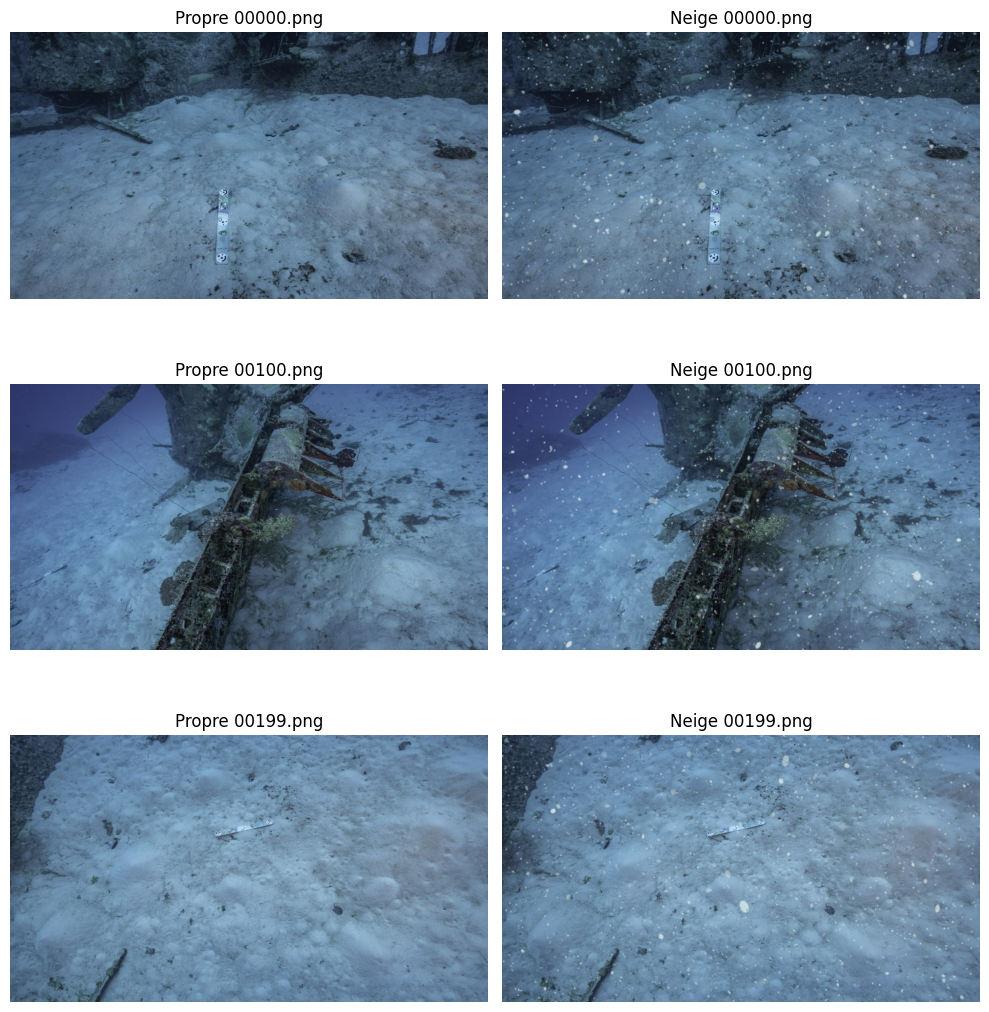

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

pick = ["00000.png", "00100.png", "00199.png"]
fig, ax = plt.subplots(3, 2, figsize=(10, 11))
for r, f in enumerate(pick):
    ax[r, 0].imshow(Image.open(f"{CLEAN_DIR}/{f}")); ax[r, 0].set_title("Propre " + f)
    ax[r, 1].imshow(Image.open(f"{INPUT_DIR}/{f}")); ax[r, 1].set_title("Neige " + f)
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.savefig(f"{WORK}/snow_check.png", dpi=100); plt.show()

In [8]:
%cd /kaggle/working
!apt-get update -qq
!apt-get install -y -qq colmap
!colmap -h | head -n 3
!git clone --recursive https://github.com/graphdeco-inria/gaussian-splatting

/kaggle/working
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1bu

In [9]:
import os
%cd /kaggle/working/gaussian-splatting
if GS_COMMIT != "HASH_COMMUN":
    !git checkout {GS_COMMIT}
    !git submodule update --init --recursive
!git rev-parse HEAD
!ls submodules

os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"
!sed -i '1i #include <cfloat>' submodules/simple-knn/simple_knn.cu
!sed -i '1i #include <cstdint>' submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h
!pip install -q plyfile tqdm opencv-python matplotlib
!pip install -q --no-build-isolation submodules/diff-gaussian-rasterization
!pip install -q --no-build-isolation submodules/simple-knn
!pip install -q --no-build-isolation submodules/fused-ssim

/kaggle/working/gaussian-splatting
54c035f7834b564019656c3e3fcc3646292f727d
diff-gaussian-rasterization  fused-ssim  simple-knn
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


In [10]:
import json, platform, subprocess, torch, cv2, numpy as np

def sh(c):
    return subprocess.run(c, shell=True, capture_output=True, text=True).stdout.strip()

env = dict(
    gpu=sh("nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv,noheader"),
    nvcc=sh("nvcc --version | tail -n 1"),
    torch=torch.__version__, torch_cuda=torch.version.cuda,
    python=platform.python_version(), numpy=np.__version__, opencv=cv2.__version__,
    colmap=sh("colmap -h | head -n 2"),
    gs_commit=sh(f"git -C {GS} rev-parse HEAD"),
    config=dict(N_IMAGES=N_IMAGES, IMG_WIDTH=IMG_WIDTH, ITERATIONS=ITERATIONS,
                EVAL_HOLD=EVAL_HOLD, CONDITION=CONDITION))
json.dump(env, open(f"{WORK}/env_{CONDITION}.json", "w"), indent=1)
print(json.dumps(env, indent=1))

{
 "gpu": "Tesla T4, 580.178.04, 15360 MiB\nTesla T4, 580.178.04, 15360 MiB",
 "nvcc": "Build cuda_12.8.r12.8/compiler.35583870_0",
 "torch": "2.11.0+cu128",
 "torch_cuda": "12.8",
 "python": "3.13.15",
 "numpy": "2.1.3",
 "opencv": "4.14.0",
 "colmap": "COLMAP 3.9.1 -- Structure-from-Motion and Multi-View Stereo\n(Commit Unknown on Unknown without CUDA)",
 "gs_commit": "54c035f7834b564019656c3e3fcc3646292f727d",
 "config": {
  "N_IMAGES": 200,
  "IMG_WIDTH": 1600,
  "ITERATIONS": 7000,
  "EVAL_HOLD": 8,
  "CONDITION": "snow"
 }
}


In [11]:
import os
os.environ["QT_QPA_PLATFORM"] = "offscreen"
%cd {GS}
!python convert.py -s {SCENE} --no_gpu 2>&1 | tee {WORK}/colmap_log_{CONDITION}.txt

/kaggle/working/gaussian-splatting
W20261028 22:49:17.166889  2047 feature_extraction.cc:403] Your current options use the maximum number of threads on the machine to extract features. Extracting SIFT features on the CPU can consume a lot of RAM per thread for large images. Consider reducing the maximum image size and/or the first octave or manually limit the number of extraction threads. Ignore this warning, if your machine has sufficient memory for the current settings.
I20261028 22:49:17.167471  2051 misc.cc:198] 
Feature extraction
I20261028 22:49:19.594909  2060 feature_extraction.cc:254] Processed file [1/200]
I20261028 22:49:19.594980  2060 feature_extraction.cc:257]   Name:            00000.png
I20261028 22:49:19.594996  2060 feature_extraction.cc:283]   Dimensions:      960 x 536
I20261028 22:49:19.595009  2060 feature_extraction.cc:286]   Camera:          #1 - OPENCV
I20261028 22:49:19.595026  2060 feature_extraction.cc:289]   Focal Length:    1152.00px
I20261028 22:49:19.595